# Themenanalyse kommunaler Bürgerhinweise

Dieses Notebook ermittelt die häufigsten Themen in den Meldetexten des Mängelmelders Konstanz. Verglichen werden zwei Vektorisierungen (Count und TF-IDF) und zwei Verfahren der Themenmodellierung (LDA und NMF). Die Ergebnisübersicht beruht auf NMF mit TF-IDF und 15 Topics. Die Texte werden dafür in Schreibweise und Wortform normalisiert. Mit `min_df=2` werden nur Begriffe berücksichtigt, die in mindestens zwei Meldungen vorkommen.

Die mitgelieferte Datei `data/raw/maengelmelder_konstanz_final_9_bereinigt.csv` ist eine bereinigte Kopie der Quelldaten. Die Änderungen sind in der [README](../README.md#daten) beschrieben. Fehlende und leere Texte werden entfernt und gezählt. Kurze Meldungen bleiben erhalten, wenn nach dem Text Preprocessing mindestens ein Token mit zwei oder mehr Buchstaben verbleibt. Meldungen ohne Merkmale im Vokabular gehen nicht in das Training ein und bleiben ohne Topic-Zuordnung.

Das Notebook mit frisch gestartetem Kernel von oben nach unten ausführen. Neue Ausgaben entstehen unter `outputs/aktuelle_analyse/`. Die gespeicherten Tabellen und das Diagramm stammen aus dem geprüften Durchlauf. Ausgewählte Ergebnisdateien liegen unter [ergebnisse/](../ergebnisse/).

## Aufbau

| Abschnitt | Schritte |
|---|---|
| Konfiguration, Daten laden und Data Profiling | 01 bis 06 |
| Text Preprocessing und Vektorisierung | 07 bis 10b |
| Ausgewählte Analyse mit NMF und TF-IDF | 11 bis 13 |
| Vergleich der Verfahren | 13a bis 13c |
| Exporte, Themenbezeichnungen und Diagramm | 14 bis 18 |
| Diskussion der Ergebnisse | Am Ende des Notebooks |

Hilfsfunktionen und Wortlisten stehen unter `src/`, die Funktionstests unter `tests/`. Die ausführlichen Modellvergleiche stehen in [03_ergaenzende_vergleiche.ipynb](03_ergaenzende_vergleiche.ipynb), frühere Versuche in [02_bisherige_vergleiche.ipynb](02_bisherige_vergleiche.ipynb). Das Hauptnotebook läuft unabhängig von beiden Vergleichsnotebooks.


In [ ]:
# Schritt 01 Umgebung und Projektordner prüfen
from pathlib import Path
from functools import partial
import sys
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

# Start aus dem Projektstamm oder einem seiner Unterordner.
work_dir = Path.cwd().resolve()
PROJECT_DIR = next((path for path in (work_dir, *work_dir.parents)
    if (path / "src" / "topic_pipeline.py").is_file()
    and (path / "notebooks").is_dir()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Projektordner mit src/ und notebooks/ nicht gefunden.")
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.topic_pipeline import (
    prepare_records, normalization_key, build_normalization_lookup, clean_text,
    select_model_documents, normalize_nmf_for_assignment, assign_topics,
    topic_dominance, describe_comparison_run, fit_comparison_run,
    summarize_comparison_runs,
)
from src import wordlists, result_view
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "NumPy:", np.__version__, "scikit-learn:", sklearn.__version__)
print("Projektordner:", PROJECT_DIR)


In [ ]:
# Schritt 02 Konfiguration

CSV_NAME = "maengelmelder_konstanz_final_9_bereinigt.csv"
TEXT_COLUMN = "text_raw"
ID_COLUMN = "id"

# Kurze Meldungen bleiben erhalten, sofern nach dem Preprocessing ein Token verbleibt.
MIN_WORDS_RAW = 1
MIN_TOKENS_CLEAN = 1
MIN_TOKEN_LENGTH = 2

# Parameter der Vektorisierung
MIN_DF = 2
MAX_DF = 0.90
NGRAM_RANGE = (1, 1)
TOKEN_PATTERN = r"(?u)\b[a-zäöüß][a-zäöüß]+\b"
SUBLINEAR_TF = True

# Ausgewähltes NMF-Modell, siehe 03_ergaenzende_vergleiche.ipynb, Schritte 11j und 11k
N_TOPICS = 15
RANDOM_STATE = 42
NMF_MAX_ITER = 500
NMF_TOL = 0.0001

# Festgelegter Vergleich mit LDA, keine erneute Suche nach Parametern.
LDA_COMPARISON_TOPICS = 10
LDA_COMPARISON_MAX_ITER = 100
LDA_COMPARISON_SEEDS = (42, 7, 21, 84, 123)
LDA_DOC_TOPIC_PRIOR = 0.1
LDA_TOPIC_WORD_PRIOR = 0.1

# Die Beschriftungen sind für den dokumentierten Modell- und Datenstand geprüft.
TOPIC_LABELS_REVIEWED = True

# Die Wortlisten stehen in src/wordlists.py.
CANONICAL_TERMS_FINAL = wordlists.CANONICAL_TERMS_FINAL
STOPWORDS_FINAL = wordlists.STOPWORDS_FINAL
NORMALIZATION_GROUPS = wordlists.NORMALIZATION_GROUPS
NORMALIZATION_KEEP = wordlists.NORMALIZATION_KEEP
NORMALIZATION_PHRASES = wordlists.NORMALIZATION_PHRASES


In [ ]:
# Schritt 03 CSV-Datei laden
csv_path = PROJECT_DIR / "data" / "raw" / CSV_NAME
if not csv_path.is_file():
    raise FileNotFoundError(f"CSV wurde nicht gefunden: {csv_path}")
df = pd.read_csv(csv_path)
print("Gefundene CSV:", csv_path)
print("Shape:", df.shape)
print("Spalten:", list(df.columns))
df.head(3)


In [ ]:
# Schritt 04 Data Profiling

required_columns = [
    "id",
    "date_created",
    TEXT_COLUMN,
    "category_parent",
    "category_child",
    "responsible",
    "lat",
    "lon",
    "address_input",
    "detail_url",
]

missing_required = [col for col in required_columns if col not in df.columns]

if missing_required:
    raise ValueError(f"Folgende erwartete Spalten fehlen: {missing_required}")

print("Anzahl Zeilen:", len(df))

# responsible, lat, lon, address_input und detail_url wurden für die Bereitstellung geleert.
print("\nFehlende Werte je Spalte:")
print(df.isna().sum())

print("\nFehlende Werte in text_raw:")
print(df[TEXT_COLUMN].isna().sum())

print("\nDubletten in text_raw:")
print(df[TEXT_COLUMN].duplicated().sum())

print("\nKategorien in category_parent:")
print(df["category_parent"].value_counts(dropna=False))

print("\nKategorien in category_child:")
print(df["category_child"].value_counts(dropna=False).head(25))

print("\nTextlängen in Wörtern:")
word_counts_raw = df[TEXT_COLUMN].dropna().astype(str).str.split().str.len()
print(word_counts_raw.describe())

print("\nBeispiele aus text_raw:")
for i, text in enumerate(df[TEXT_COLUMN].dropna().astype(str).head(5), start=1):
    print(f"\nBeispiel {i}:")
    print(text[:500])


In [ ]:
# Schritt 05 Arbeitsdatensatz erstellen

df_work, record_counts = prepare_records(df, TEXT_COLUMN, MIN_WORDS_RAW, ID_COLUMN)

print("Ausgangszeilen:", record_counts["input"])
print("Entfernte vollständig identische Datensätze:", record_counts["duplicates"])
print("Entfernte fehlende Texte:", record_counts["missing"])
print("Entfernte leere Texte:", record_counts["empty"])
print("Entfernte Texte unter der Mindestlänge:", record_counts["raw_short"])
print("Meldungen im Arbeitsdatensatz:", record_counts["remaining"])
print("Weitere Meldungen mit gleichem Text, beibehalten:", record_counts["text_repetitions"])

df_work[[ID_COLUMN, TEXT_COLUMN, "category_parent", "category_child", "word_count_raw"]].head(10)


In [ ]:
# Schritt 06 Ausgabeordner festlegen

OUTPUT_DIR = PROJECT_DIR / "outputs" / "aktuelle_analyse"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output-Ordner:")
print(OUTPUT_DIR)


In [ ]:
# Schritt 07 Text Preprocessing konfigurieren
NORMALIZATION_LOOKUP = build_normalization_lookup(
    dict(CANONICAL_TERMS_FINAL), NORMALIZATION_GROUPS
)
NORMALIZED_STOPWORDS = {normalization_key(word) for word in STOPWORDS_FINAL}
NORMALIZED_STOPWORDS -= {normalization_key(word) for word in NORMALIZATION_KEEP}

clean_current_text = partial(
    clean_text, lookup=NORMALIZATION_LOOKUP, stopwords=NORMALIZED_STOPWORDS,
    min_token_length=MIN_TOKEN_LENGTH, phrases=NORMALIZATION_PHRASES,
)


In [ ]:
# Schritt 08 Text Preprocessing anwenden

# Für jeden Lauf eine neue Kopie des Arbeitsdatensatzes erzeugen.
df_model = df_work.copy()
df_model["text_clean"] = df_model[TEXT_COLUMN].apply(clean_current_text)
df_model["word_count_clean"] = df_model["text_clean"].str.split().str.len()

before_clean_filter = len(df_model)
df_model = df_model[df_model["word_count_clean"] >= MIN_TOKENS_CLEAN].copy()
after_clean_filter = len(df_model)
df_model = df_model.reset_index(drop=True)

print("Zeilen vor Textfilter:", before_clean_filter)
print("Zeilen nach Textfilter:", after_clean_filter)
print("Entfernte Meldungen:", before_clean_filter - after_clean_filter)
print("\nVerteilung der Wortanzahl nach Text Preprocessing:")
print(df_model["word_count_clean"].describe())

if df_model.empty:
    raise ValueError("Nach dem Text Preprocessing sind keine Meldungen vorhanden.")


In [ ]:
# Schritt 09 Bereinigte Texte anhand von Beispielen ansehen

print("Beispiele vorher/nachher:")

for _, row in df_model[[TEXT_COLUMN, "text_clean"]].head(10).iterrows():
    print("\nRAW:")
    print(row[TEXT_COLUMN][:300])
    print("CLEAN:")
    print(row["text_clean"])


In [ ]:
# Schritt 10 Texte mit CountVectorizer und TfidfVectorizer vektorisieren

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts_clean = df_model["text_clean"].tolist()

count_vectorizer = CountVectorizer(
    min_df=MIN_DF,
    max_df=MAX_DF,
    token_pattern=TOKEN_PATTERN,
    ngram_range=NGRAM_RANGE
)

tfidf_vectorizer = TfidfVectorizer(
    min_df=MIN_DF,
    max_df=MAX_DF,
    token_pattern=TOKEN_PATTERN,
    ngram_range=NGRAM_RANGE,
    sublinear_tf=SUBLINEAR_TF,
    norm="l2",
    use_idf=True,
    smooth_idf=True
)

X_count = count_vectorizer.fit_transform(texts_clean)
X_tfidf = tfidf_vectorizer.fit_transform(texts_clean)

print("Anzahl Dokumente:", len(texts_clean))
print("Count-Matrix:", X_count.shape)
print("TF-IDF-Matrix:", X_tfidf.shape)

print("\nBeispiele aus Count-Vokabular:")
print(count_vectorizer.get_feature_names_out()[:30])

print("\nBeispiele aus TF-IDF-Vokabular:")
print(tfidf_vectorizer.get_feature_names_out()[:30])


In [ ]:
# Kontrolle vor der Modellierung

print("Eingelesene Meldungen:", len(df))
print("Meldungen nach Text Preprocessing:", len(df_model))
print("Count-Matrix:", X_count.shape)
print("TF-IDF-Matrix:", X_tfidf.shape)
print(
    "Meldungen ohne Merkmale in der Count-Matrix:",
    int((X_count.getnnz(axis=1) == 0).sum())
)
print(
    "Meldungen ohne Merkmale in der TF-IDF-Matrix:",
    int((X_tfidf.getnnz(axis=1) == 0).sum())
)

# Kontrollieren, dass nach dem Preprocessing keine leeren Texte verbleiben.
assert df_model[TEXT_COLUMN].notna().all()
assert (df_model["word_count_clean"] >= MIN_TOKENS_CLEAN).all()
assert len(df_model) == X_count.shape[0] == X_tfidf.shape[0]

# Funktionstests mit künstlichen Eingaben stehen in tests/test_topic_pipeline.py.
print("Kontrolle der Textfilter: bestanden")


In [ ]:
# Schritt 10b Meldungen ohne Merkmale erfassen

if not np.array_equal(
    count_vectorizer.get_feature_names_out(), tfidf_vectorizer.get_feature_names_out()
):
    raise ValueError("Count und TF-IDF verwenden unterschiedliche Vokabulare.")

model_mask, df_fit, X_count_fit, X_tfidf_fit, df_without_features = select_model_documents(
    df_model, X_count, X_tfidf
)
N_ANALYSIS_DOCS = len(df_model)
if N_ANALYSIS_DOCS == 0:
    raise ValueError("Nach dem Text Preprocessing sind keine Meldungen vorhanden.")

# Das Vokabular wurde in Schritt 10 festgelegt, die IDF-Gewichte wurden dort berechnet.
# Grundlage waren alle Meldungen nach dem Text Preprocessing.
# Für das Modelltraining werden anschließend die Zeilen ohne Merkmale ausgeschlossen.
assert len(df_fit) + len(df_without_features) == N_ANALYSIS_DOCS
assert len(df_fit) == X_count_fit.shape[0] == X_tfidf_fit.shape[0]
assert (X_count_fit.getnnz(axis=1) > 0).all()
assert (X_tfidf_fit.getnnz(axis=1) > 0).all()

print("Meldungen nach Text Preprocessing:", N_ANALYSIS_DOCS)
print("Meldungen mit Merkmalen für das Modelltraining:", len(df_fit))
print("Nicht zugeordnet, da keine Merkmale im Vokabular:", len(df_without_features))
print("Count-Matrix für das Modelltraining:", X_count_fit.shape)
print("TF-IDF-Matrix für das Modelltraining:", X_tfidf_fit.shape)
print("Meldungen ohne Merkmale in den Trainingsmatrizen:", 0)
print("Bezugsgröße der Prozentanteile:", N_ANALYSIS_DOCS)
print("Kontrolle der Auswahl: bestanden")


In [ ]:
# Schritt 11 Das ausgewählte NMF-Modell trainieren

from sklearn.decomposition import NMF

if len(df_fit) == 0:
    raise ValueError("Keine Meldungen mit Merkmalen vorhanden. Daten und Vokabularfilter prüfen.")
if not isinstance(N_TOPICS, int) or isinstance(N_TOPICS, bool) or N_TOPICS < 1:
    raise ValueError("N_TOPICS muss eine positive ganze Zahl sein.")
if N_TOPICS > min(X_tfidf_fit.shape):
    raise ValueError("Für diese NMF-Initialisierung gibt es zu wenige Meldungen oder Merkmale.")

nmf_model = NMF(
    n_components=N_TOPICS,
    random_state=RANDOM_STATE,
    init="nndsvda",
    solver="cd",
    beta_loss="frobenius",
    max_iter=NMF_MAX_ITER,
    tol=NMF_TOL,
    alpha_W=0.0,
    alpha_H="same",
    l1_ratio=0.0,
    shuffle=False,
)
nmf_doc_topic_raw = nmf_model.fit_transform(X_tfidf_fit.copy())

print("NMF Dokument-Topic-Matrix:", nmf_doc_topic_raw.shape)
print("Trainingsiterationen:", nmf_model.n_iter_)


In [ ]:
# Schritt 11a NMF-Koeffizienten für L2-normierte Topic-Vektoren berechnen

# Die ursprünglichen Komponenten und Koeffizienten bleiben unverändert erhalten.
nmf_doc_topic, nmf_components_unit = normalize_nmf_for_assignment(
    nmf_doc_topic_raw, nmf_model.components_
)
print("NMF-Zuordnung verwendet Koeffizienten für L2-normierte Topic-Vektoren.")
print("Technische Kontrolle der NMF-Skalierung: bestanden")


In [ ]:
# Schritt 11b Topic-Zuordnung und nicht zugeordnete Meldungen erfassen

nmf_assignments = assign_topics(nmf_doc_topic, model_mask, df_model.index)

status_rows = []
for method, assignments in (("NMF", nmf_assignments),):
    if not assignments.index.equals(df_model.index):
        raise RuntimeError("Die Reihenfolge der Zuordnungen passt nicht zu den Meldungen.")
    if assignments.loc[~model_mask, "Topic"].notna().any():
        raise RuntimeError("Eine Meldung ohne Merkmale hat unzulässigerweise ein Topic erhalten.")
    assigned_count = int(assignments["Topic"].notna().sum())
    unassigned_count = int(assignments["Topic"].isna().sum())
    assert assigned_count + unassigned_count == N_ANALYSIS_DOCS
    status_rows.append({
        "Verfahren": method,
        "Anzahl Topics": N_TOPICS,
        "Meldungen nach Text Preprocessing": N_ANALYSIS_DOCS,
        "Topic zugeordnet": assigned_count,
        "Nicht zugeordnet": unassigned_count,
        "Davon ohne Merkmale": int((assignments["Status"] == "Keine Merkmale im Vokabular").sum()),
        "Davon ohne positive Topic-Gewichte": int((assignments["Status"] == "Keine positiven Topic-Gewichte").sum()),
        "Anteil nicht zugeordnet in Prozent": round(100 * unassigned_count / N_ANALYSIS_DOCS, 1),
        "Mehrere Topics mit gleichem Höchstwert": int(assignments["Gleicher Höchstwert"].sum()),
    })
    print(f"{method}: {assigned_count} zugeordnet, {unassigned_count} nicht zugeordnet")

assignment_summary = pd.DataFrame(status_rows)
display(assignment_summary)
print("Kontrolle der Zuordnung: bestanden")


In [ ]:
# Schritt 11c Dominanz des stärksten Topics ergänzend erfassen

nmf_dominance, nmf_ties = topic_dominance(nmf_doc_topic)
nmf_assignments["Dominanz"] = pd.Series(nmf_dominance, index=df_fit.index).reindex(df_model.index)
if not np.array_equal(nmf_ties, nmf_assignments.loc[df_fit.index, "Gleicher Höchstwert"].to_numpy()):
    raise RuntimeError("Die Kontrolle gleicher Höchstwerte stimmt nicht mit den Zuordnungen überein.")

print("Dominanz berechnet, keine Meldungen anhand eines Schwellenwerts ausgeschlossen.")


In [ ]:
# Schritt 12 Top-Begriffe und Kohärenz des ausgewählten Modells

import gensim
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel

COHERENCE_TOP_N = 10
COHERENCE_WINDOW_SIZE = 110
features_nmf = tfidf_vectorizer.get_feature_names_out()
components = nmf_model.components_
if ((components > 0).sum(axis=1) < COHERENCE_TOP_N).any():
    raise ValueError("Mindestens ein Topic enthält zu wenige positive Begriffe für die Kohärenzberechnung.")

# Kohärenz aus den aktuellen Texten mit zehn Begriffen je Topic und Fenstergröße 110 berechnen.
coherence_texts = df_model["text_clean"].str.split().tolist()
coherence_dictionary = Dictionary(coherence_texts)
topic_indices = np.argsort(-components, axis=1, kind="stable")[:, :COHERENCE_TOP_N]
topic_words = [features_nmf[indices].tolist() for indices in topic_indices]
coherence_per_topic = np.asarray(CoherenceModel(
    topics=topic_words,
    texts=coherence_texts,
    dictionary=coherence_dictionary,
    coherence="c_v",
    topn=COHERENCE_TOP_N,
    window_size=COHERENCE_WINDOW_SIZE,
    processes=1,
).get_coherence_per_topic(), dtype=float)
if not np.isfinite(coherence_per_topic).all():
    raise RuntimeError("Die Kohärenz ist nicht für alle Topics berechenbar.")

nmf_topics = pd.DataFrame({
    "Topic": np.arange(1, N_TOPICS + 1),
    "Top-Begriffe": [", ".join(words) for words in topic_words],
    "c_v": coherence_per_topic,
})
display(nmf_topics)
print("Mittlerer Kohärenzwert c_v:", round(float(coherence_per_topic.mean()), 4))


In [18]:
# Schritt 13 Technische Themenübersicht und Kontrollzahlen erstellen

counts = nmf_assignments["Topic"].value_counts().reindex(range(1, N_TOPICS + 1), fill_value=0)
nmf_summary = nmf_topics.copy()
nmf_summary["Anzahl Meldungen"] = nmf_summary["Topic"].map(counts).astype(int)
nmf_summary["Anteil Prozent"] = 100 * nmf_summary["Anzahl Meldungen"] / N_ANALYSIS_DOCS
nmf_summary["Bezugsmenge Meldungen"] = N_ANALYSIS_DOCS
nmf_summary = nmf_summary.sort_values(
    ["Anzahl Meldungen", "Topic"], ascending=[False, True], kind="stable"
).reset_index(drop=True)
assigned_count = int(nmf_assignments["Topic"].notna().sum())
unassigned_count = int(nmf_assignments["Topic"].isna().sum())
if int(nmf_summary["Anzahl Meldungen"].sum()) != assigned_count:
    raise RuntimeError("Die Topic-Häufigkeiten passen nicht zur Anzahl zugeordneter Meldungen.")
if assigned_count + unassigned_count != N_ANALYSIS_DOCS:
    raise RuntimeError("Die Zuordnungen passen nicht zur Bezugsgröße der Prozentanteile.")

model_selection = pd.DataFrame([{
    "Verfahren": "NMF",
    "Vektorisierung": "TF-IDF",
    "Textvariante": "Normalisierte Schreibweisen und Wortformen",
    "Anzahl Topics": N_TOPICS,
    "min_df": MIN_DF,
    "Seed": RANDOM_STATE,
    "Eingelesene Meldungen": len(df),
    "Meldungen im Arbeitsdatensatz": len(df_work),
    "Nach Text Preprocessing": N_ANALYSIS_DOCS,
    "Durch Textfilter ausgeschlossen": len(df_work) - N_ANALYSIS_DOCS,
    "Merkmale": len(features_nmf),
    "Für das Modelltraining": len(df_fit),
    "Zugeordnet": assigned_count,
    "Nicht zugeordnet": unassigned_count,
    "c_v Mittelwert": float(coherence_per_topic.mean()),
    "c_v Minimum": float(coherence_per_topic.min()),
    "Iterationen": int(nmf_model.n_iter_),
    "Dominanzfilter aktiv": False,
}])
display(nmf_summary.round({"Anteil Prozent": 1, "c_v": 4}))
print(model_selection[["Verfahren", "Vektorisierung", "Anzahl Topics", "min_df", "Merkmale", "Zugeordnet", "Nicht zugeordnet", "c_v Mittelwert"]].round(4).to_string(index=False))
print("Bezugsgröße der Prozentanteile:", N_ANALYSIS_DOCS)
print("Technische Kontrolle der integrierten Analyse: bestanden")


,Topic,Top-Begriffe,c_v,Anzahl Meldungen,Anteil Prozent,Bezugsmenge Meldungen
0,1,"beleuchtung, leuchten, kurve, licht, weitere, ...",0.4776,580,21.0,2759
1,13,"wasser, verstopft, läuft, ab, ablauf, gulli, r...",0.5573,239,8.7,2759
2,3,"müll, illegaler, glascontainer, altglascontain...",0.3774,223,8.1,2759
3,2,"fahrrad, herrenloses, moeglichkeit, sattel, dr...",0.4136,213,7.7,2759
4,8,"ampel, fußgänger, grün, kreuzung, rot, licht, ...",0.5841,192,7.0,2759
5,5,"straße, entlang, leuchten, licht, abgemeldeter...",0.4314,190,6.9,2759
6,15,"fahrzeug, parkplatz, kennzeichen, strassenrand...",0.3947,177,6.4,2759
7,6,"schild, boden, umgefahren, erkennen, verdreht,...",0.5196,175,6.3,2759
8,4,"gehweg, wächst, hecke, zugewachsen, ragt, fußg...",0.3663,160,5.8,2759
9,14,"spielplatz, mülleimer, schlagloch, überfüllt, ...",0.3327,160,5.8,2759


Verfahren Vektorisierung  Anzahl Topics  min_df  Merkmale  Zugeordnet  Nicht zugeordnet  c_v Mittelwert
      NMF         TF-IDF             15       2      2460        2731                28          0.4383
Bezugsgröße der Prozentanteile: 2759
Technische Kontrolle der integrierten Analyse: bestanden


## Vergleich der Verfahren

Das ausgewählte Modell wird mit NMF auf Count-Vektoren und LDA auf Count-Vektoren verglichen. Der erste Vergleich untersucht die Vektorisierung bei gleicher Modellgröße, der zweite das Verfahren der Themenmodellierung (LDA statt NMF).

| Konfiguration | Topics | Läufe | Verwendung |
|---|---:|---|---|
| NMF mit TF-IDF | 15 | 1, Seed 42 | Ausgewählte Analyse |
| NMF mit Count | 15 | 1, Seed 42 | Vergleich der Vektorisierungen |
| LDA mit Count | 10 | 5, Seeds 42, 7, 21, 84, 123 | Vergleich der Verfahren, je 100 Iterationen |

Count erfasst die Häufigkeit jedes Begriffs in einer Meldung. TF-IDF berücksichtigt zusätzlich dessen Verbreitung im gesamten Korpus. In dieser Analyse werden die Termfrequenzen logarithmisch skaliert und die TF-IDF-Dokumentvektoren L2-normiert.

Alle Modelle verwenden dieselben Texte und dasselbe Vokabular. Die Kohärenz `c_v` wird mit zehn Begriffen je Topic berechnet. Für den Vergleich mit den Haupt- und Unterkategorien werden NMI, AMI, ARI und Reinheit ermittelt. Die folgende Tabelle zeigt davon AMI für Haupt- und Unterkategorien sowie die Reinheit der Hauptkategorien. Die Kategorienkennzahlen beziehen sich auf dieselben 2.731 Meldungen, die in allen Modellläufen einem Topic zugeordnet wurden. Die Kategorien dienen nur der Bewertung und gehen nicht in das Modelltraining ein.


In [ ]:
# Schritt 13a Gemeinsame Grundlage für den Vergleich der Verfahren
from sklearn.base import clone
from sklearn.decomposition import LatentDirichletAllocation

comparison_context = {
    "documents": df_model, "fit_index": df_fit.index, "mask": model_mask,
    "features": features_nmf, "coherence_texts": coherence_texts,
    "coherence_dictionary": coherence_dictionary,
    "top_n": COHERENCE_TOP_N, "window_size": COHERENCE_WINDOW_SIZE,
}


In [ ]:
# Schritt 13b Die festgelegten Vergleichsmodelle berechnen

if not {"category_parent", "category_child"}.issubset(df_model.columns):
    raise ValueError("Für den Vergleich fehlen die vorhandenen Meldekategorien.")
if not np.array_equal(count_vectorizer.get_feature_names_out(), features_nmf):
    raise ValueError("Count und TF-IDF müssen dasselbe Vokabular verwenden.")
if not df_model.index[model_mask].equals(df_fit.index):
    raise ValueError("Die Reihenfolge der Trainingsmeldungen stimmt nicht überein.")
if (len(LDA_COMPARISON_SEEDS) != 5 or len(set(LDA_COMPARISON_SEEDS)) != 5
        or any(isinstance(s, bool) or not isinstance(s, int) or s < 0 for s in LDA_COMPARISON_SEEDS)):
    raise ValueError("Für LDA werden fünf unterschiedliche nicht negative Seeds benötigt.")

# Das ausgewählte Modell ist bereits trainiert.
# Die Vergleichsmodelle werden zusätzlich trainiert und verändern es nicht.
method_runs = {("NMF", "TF-IDF", RANDOM_STATE): describe_comparison_run(
    nmf_model, nmf_doc_topic, "NMF", "TF-IDF", topic_coherence=coherence_per_topic, **comparison_context,
)}
print("[1/7] NMF mit TF-IDF aus der Hauptanalyse übernommen")
print("[2/7] NMF mit Count, Seed", RANDOM_STATE, flush=True)
method_runs[("NMF", "Count", RANDOM_STATE)] = fit_comparison_run(
    clone(nmf_model), X_count_fit, "NMF", "Count", **comparison_context,
)
for position, seed in enumerate(LDA_COMPARISON_SEEDS, start=3):
    print(f"[{position}/7] LDA mit Count, Seed {seed}", flush=True)
    model = LatentDirichletAllocation(
        n_components=LDA_COMPARISON_TOPICS, max_iter=LDA_COMPARISON_MAX_ITER,
        learning_method="batch", doc_topic_prior=LDA_DOC_TOPIC_PRIOR,
        topic_word_prior=LDA_TOPIC_WORD_PRIOR, random_state=seed, evaluate_every=-1,
    )
    method_runs[("LDA", "Count", seed)] = fit_comparison_run(model, X_count_fit, "LDA", "Count", **comparison_context)


In [21]:
# Schritt 13c Kennzahlen und Themen des Vergleichs anzeigen
(method_comparison_runs, method_comparison_topics, method_comparison_assignments,
 method_comparison_summary, comparison_common, comparison_display) = summarize_comparison_runs(
    method_runs, df_model, features_nmf, ID_COLUMN
)
with pd.option_context("display.max_columns", None, "display.max_colwidth", None):
    display(comparison_display[[
        "Konfiguration", "Topics", "Läufe", "c_v Mittelwert", "AMI Haupt", "AMI Unter", "Reinheit Haupt",
    ]])
print("Datenbasis der Kategorienkennzahlen:", int(comparison_common.sum()), "gemeinsam zugeordnete Meldungen")
print("Fehlende Kategorien in dieser Menge:",
      ", ".join(f"{level}: {int(method_comparison_runs[f'Ohne Kategorie {level}'].iloc[0])}" for level in ("Haupt", "Unter")))
print("Bei LDA Mittelwert ± Standardabweichung über fünf Seeds, bei NMF jeweils Seed 42.")
print("Die zusätzlichen Topic-Listen zeigen Seed 42, nicht eine Mittelung der LDA-Topics.")
with pd.option_context("display.max_columns", None, "display.max_colwidth", None):
    display(method_comparison_topics.loc[
        method_comparison_topics["Seed"].eq(RANDOM_STATE) & method_comparison_topics["Vektorisierung"].eq("Count"),
        ["Verfahren", "Topic", "Top-Begriffe", "Anzahl Meldungen"],
    ].reset_index(drop=True))
print("Verglichene Konfigurationen: 3")
print("Modellläufe im Vergleich: 7, davon 6 zusätzlich trainiert")
print("Technische Kontrolle des Verfahrensvergleichs: bestanden")


,Konfiguration,Topics,Läufe,c_v Mittelwert,AMI Haupt,AMI Unter,Reinheit Haupt
0,NMF mit TF-IDF,15,1,0.4383,0.3047,0.4061,0.6719
1,NMF mit Count,15,1,0.5451,0.3352,0.3952,0.7118
2,LDA mit Count,10,5,0.3365 ± 0.0254,0.1778 ± 0.0143,0.2015 ± 0.0171,0.5879 ± 0.0118


Datenbasis der Kategorienkennzahlen: 2731 gemeinsam zugeordnete Meldungen
Fehlende Kategorien in dieser Menge: Haupt: 0, Unter: 0
Bei LDA Mittelwert ± Standardabweichung über fünf Seeds, bei NMF jeweils Seed 42.
Die zusätzlichen Topic-Listen zeigen Seed 42, nicht eine Mittelung der LDA-Topics.


,Verfahren,Topic,Top-Begriffe,Anzahl Meldungen
0,NMF,1,"beleuchtung, leuchten, licht, schiffslaende, nachts, treppe, kreuzung, bruecke, bushaltestelle, meldung",654
1,NMF,2,"straße, verschmutzt, auto, gibt, nummernschilder, strassenrand, zustand, ausserdem, fahrzeug, abgemeldeter",211
2,NMF,3,"müll, illegaler, mülleimer, parkplatz, verteilt, illegal, entsorgung, entsorgen, spielplatz, herum",318
3,NMF,4,"fahrrad, fahrradstaender, bewegt, platz, sattel, herrenloses, raeder, angeschlossen, drei, blockieren",259
4,NMF,5,"geraeumt, autos, gefährlich, ja, gar, fahrspuren, wenig, radweg, einfach, radler",72
5,NMF,6,"schild, bushaltestelle, meter, rad, radler, erkennen, ende, stellen, heuss, theodor",174
6,NMF,7,"radweg, scherben, regelmaessig, wollmatingen, gesamte, bhf, glasscherben, kreuzung, entlang, gereinigt",149
7,NMF,8,"gehweg, rad, pflanzen, mittlerweile, tannenhof, kinderwagen, personen, fuehrt, glasscherben, laub",165
8,NMF,9,"radfahrer, sperrung, gesperrt, wegen, umfahren, baustelle, gemacht, verkehrsmittel, umleitungen, umleitung",55
9,NMF,10,"baum, entlang, ueberwuchert, äste, gibt, wurzeln, kleinen, inzwischen, fuehrt, biber",118


Verglichene Konfigurationen: 3
Modellläufe im Vergleich: 7, davon 6 zusätzlich trainiert
Technische Kontrolle des Verfahrensvergleichs: bestanden


### Einordnung des Vergleichs

Beide NMF-Varianten stimmen in diesem Vergleich deutlich besser mit den Meldekategorien überein als LDA. Die Gruppierungen von LDA unterscheiden sich außerdem stark zwischen den Seeds. Die ausführliche Untersuchung dazu steht in [03_ergaenzende_vergleiche.ipynb](03_ergaenzende_vergleiche.ipynb), Schritt 11l. Für LDA zeigt die Vergleichstabelle Mittelwert und Standardabweichung aus fünf Läufen. Die angezeigten LDA-Topics stammen aus dem Lauf mit Seed 42.

Count erreicht bei NMF eine höhere Kohärenz und eine höhere Übereinstimmung mit den Hauptkategorien. Einzelne Count-Topics enthalten jedoch vorwiegend allgemeine Formulierungen und lassen sich nur schwer als konkretes Thema benennen.

Für eine inhaltliche Prüfung wurden die Anliegen aus 50 Meldungen manuell zusammengefasst und die Zuordnungen beider NMF-Varianten anschließend mithilfe von KI gegenübergestellt. Mit TF-IDF ließen sich dabei mehrere Themen klarer erkennen, etwa Ampeln, Sperrmüll und abgestellte Roller. Für die Ergebnisübersicht wurde deshalb NMF mit TF-IDF ausgewählt.

Die Wahl von 15 Topics beruht auf dem Vergleich in [03_ergaenzende_vergleiche.ipynb](03_ergaenzende_vergleiche.ipynb), Schritt 11j. Gegenüber zehn Topics entstanden zusätzliche Gruppen, unter anderem für Sperrmüll und abgemeldete Fahrzeuge.


In [ ]:
# Schritt 14 Die aktuellen Ergebnisse speichern

import hashlib
import json
import platform
import zipfile
import scipy

# Keine originalen Texte, Adressen oder Koordinaten in den Zuordnungsexport übernehmen.
assignment_export = nmf_assignments.copy()
assignment_export.insert(0, "ID", df_model[ID_COLUMN].astype("string").str.strip().to_numpy())
export_tables = {
    "themenuebersicht_nmf.csv": nmf_summary,
    "zuordnung_nmf.csv": assignment_summary,
    "zuordnungen_nmf.csv": assignment_export,
    "modellauswahl.csv": model_selection,
    "vergleich_verfahren_laeufe.csv": method_comparison_runs,
    "vergleich_verfahren_zusammenfassung.csv": method_comparison_summary,
    "topics_verfahren.csv": method_comparison_topics,
    "zuordnungen_verfahren.csv": method_comparison_assignments,
}
written_paths = []
for filename, table in export_tables.items():
    path = OUTPUT_DIR / filename
    table.to_csv(path, index=False, sep=";", encoding="utf-8-sig", lineterminator="\n")
    written_paths.append(path)

text_frame = df_model[[ID_COLUMN, "text_clean"]].copy()
text_frame[ID_COLUMN] = text_frame[ID_COLUMN].astype("string").str.strip()
settings = {
    "stand": "Integrierte Analyse mit kompaktem Verfahrensvergleich",
    "hauptnotebook": "01_themenanalyse.ipynb",
    "dateiname_csv": CSV_NAME,
    "daten_sha256": hashlib.sha256(csv_path.read_bytes()).hexdigest(),
    "texte_sha256": hashlib.sha256(text_frame.to_csv(index=False, lineterminator="\n").encode("utf-8")).hexdigest(),
    "textverarbeitung": {
        "variante": "Normalisierte Schreibweisen und Wortformen",
        "min_words_raw": MIN_WORDS_RAW,
        "min_tokens_clean": MIN_TOKENS_CLEAN,
        "min_token_length": MIN_TOKEN_LENGTH,
        "stopwoerter": sorted(NORMALIZED_STOPWORDS),
        "begriffszuordnungen": NORMALIZATION_LOOKUP,
        "beibehalten": sorted(NORMALIZATION_KEEP),
        "entfernte_floskeln": list(NORMALIZATION_PHRASES),
    },
    "parameter_count": count_vectorizer.get_params(),
    "parameter_tfidf": tfidf_vectorizer.get_params(),
    "parameter_nmf": nmf_model.get_params(),
    "verfahrenvergleich": {
        "modelle": [{"verfahren": method, "vektorisierung": vectorization,
                     "seed": seed, "parameter": run["model"].get_params()}
                    for (method, vectorization, seed), run in method_runs.items()],
        "gemeinsame_zuordnungen": int(comparison_common.sum()),
        "gemeinsame_ids_sha256": hashlib.sha256("\n".join(sorted(
            df_model.loc[comparison_common, ID_COLUMN].astype("string").str.strip()
        )).encode("utf-8")).hexdigest(),
        "kategorien": ["category_parent", "category_child"],
        "fehlende_kategorien": "In Kennzahlen ausgeschlossen und je Kategorieebene gezählt",
        "nmi_ami_normalisierung": "arithmetic",
        "standardabweichung": "ddof=1; bei einem Lauf nicht berechenbar, bleibt leer",
        "grundlage": "Gleiche Texte und Vokabulare, gemeinsame Topic-Zuordnung aller sieben Läufe",
        "nmf": "15 Topics, Seed 42; ausgewähltes TF-IDF-Modell nicht erneut trainiert",
        "lda": "10 Topics, 100 Iterationen, fünf festgelegte Seeds; kein neuer Parametervergleich",
        "umfang": "NMF/TF-IDF plus NMF/Count und fünf LDA/Count-Läufe, keine neue inhaltliche Bewertung",
    },
    "zuordnung": "argmax positiver NMF-Koeffizienten für L2-normierte Topic-Vektoren",
    "dominanz": "max(w)/sum(w), nur Diagnose, kein Schwellenwert für die Zählung",
    "bezugsmenge_prozent": N_ANALYSIS_DOCS,
    "c_v": {"topn": COHERENCE_TOP_N, "window_size": COHERENCE_WINDOW_SIZE, "processes": 1},
    "themenbezeichnungen_geprueft": TOPIC_LABELS_REVIEWED,
    "versionen": {
        "python": platform.python_version(), "numpy": np.__version__,
        "pandas": pd.__version__, "scipy": scipy.__version__,
        "sklearn": sklearn.__version__, "gensim": gensim.__version__,
    },
    "sha256_ausgaben": {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in written_paths},
}
settings_path = OUTPUT_DIR / "einstellungen_analyse.json"
settings_path.write_text(json.dumps(settings, ensure_ascii=False, indent=2, default=str) + "\n", encoding="utf-8")
written_paths.append(settings_path)

archive_path = OUTPUT_DIR / "integration_nmf15.zip"
with zipfile.ZipFile(archive_path, "w", compression=zipfile.ZIP_DEFLATED) as bundle:
    for path in written_paths:
        bundle.write(path, arcname=path.name)
print("Gespeichert:", archive_path.resolve())


## Ergebnisübersicht

Die Übersicht und das Diagramm zeigen elf benennbare Themen. Die Meldungen der vier inhaltlich gemischten Topics werden zusammen mit den 28 Meldungen ohne Topic-Zuordnung als „nicht nach Themen aufgeschlüsselt“ ausgewiesen. Alle 15 Topics bleiben in der technischen Übersicht in Schritt 13 enthalten. Die vollständige Tabelle mit Themenbezeichnungen liegt unter `ergebnisse/nmf_topics_beschriftet.csv`.

Die Bezeichnungen beruhen auf den Top-Begriffen, der Verteilung der Meldekategorien und der Durchsicht ausgewählter Meldungen. „Gehwege“, „Radwege“ und „Fahrzeuge und Parkplätze“ fassen verschiedene Mängel an der jeweiligen Infrastruktur zusammen. Die Beispielsätze sind sinngemäß formuliert und keine Originalzitate.

Jede zugeordnete Meldung zählt beim Topic mit dem höchsten positiven Koeffizienten. Die NMF-Koeffizienten werden dafür passend zu L2-normierten Topic-Vektoren skaliert. Ein zusätzlicher Filter nach Dominanz wird nicht verwendet. Die Prozentanteile beziehen sich auf alle 2.759 Meldungen nach dem Text Preprocessing, einschließlich der Meldungen ohne Topic-Zuordnung.


In [ ]:
# Schritt 15 Die fünfzehn Topics beschriften
# Die geprüften Namen und Beschreibungen stehen in src/result_view.py.
LABEL_DATA_SHA256 = result_view.LABEL_DATA_SHA256
LABELS_VERSION = result_view.LABELS_VERSION
TOPIC_DESCRIPTIONS = result_view.TOPIC_DESCRIPTIONS
EXPECTED_TOPIC_WORDS = result_view.EXPECTED_TOPIC_WORDS

if not TOPIC_LABELS_REVIEWED:
    raise RuntimeError("Die Themenbezeichnungen sind noch nicht für die Darstellung freigegeben.")
if N_TOPICS != 15 or MIN_DF != 2 or nmf_model.random_state != 42:
    raise ValueError("Diese Beschriftungen gehören zur ausgewählten NMF-Analyse mit 15 Topics.")
if hashlib.sha256(csv_path.read_bytes()).hexdigest() != LABEL_DATA_SHA256:
    raise ValueError("Der Datenstand hat sich geändert. Die Themenbezeichnungen müssen erneut geprüft werden.")

nmf_labeled_topics = result_view.describe_selected_topics(nmf_summary, TOPIC_DESCRIPTIONS, EXPECTED_TOPIC_WORDS)
print("Beschriftete Topics:", len(nmf_labeled_topics))
print("Schwerpunkte für die Ergebnisübersicht:", int(nmf_labeled_topics["In Ergebnisübersicht"].sum()))
print("Thematisch uneinheitliche Topics:", int((~nmf_labeled_topics["In Ergebnisübersicht"]).sum()))


In [24]:
# Schritt 16 Die Ergebnisübersicht und ihren Umfang erstellen

nmf_labeled_topics, decision_table_final, decision_coverage, not_presented_reasons = result_view.build_result_view(
    nmf_labeled_topics, nmf_assignments, N_ANALYSIS_DOCS
)
display(decision_table_final[["Rang", "Thema", "Anzahl Meldungen", "Anteil Prozent"]].style.hide(axis="index").format(
    {"Anzahl Meldungen": "{:,.0f}", "Anteil Prozent": "{:.1f}"}, decimal=",", thousands="."
))
display(decision_coverage.round({"Anteil Prozent": 1}))
print("Meldungen in der Ergebnisübersicht:", int(decision_table_final["Anzahl Meldungen"].sum()))
print("Nicht nach Themen aufgeschlüsselt:", int(not_presented_reasons["Anzahl Meldungen"].sum()))
print("Bezugsgröße der Prozentanteile:", N_ANALYSIS_DOCS)
print("Kein zusätzlicher Filter nach Dominanz, die Modellzuordnungen bleiben unverändert.")
print("Technische Kontrolle der Ergebnisdarstellung: bestanden")


Rang,Thema,Anzahl Meldungen,Anteil Prozent
1,Straßenbeleuchtung,580,"21,0"
2,Müllablagerungen,223,"8,1"
3,Abgestellte Fahrräder,213,"7,7"
4,Ampeln und Straßenquerungen,192,"7,0"
5,Fahrzeuge und Parkplätze,177,"6,4"
6,Beschilderung,175,"6,3"
7,Gehwege,160,"5,8"
8,Radwege,129,"4,7"
9,Glasscherben,57,"2,1"
10,Sperrmüll,46,"1,7"


,Bereich,Anzahl Meldungen,Anteil Prozent,Bezugsmenge Meldungen
0,In der Themenübersicht dargestellt,1994,72.3,2759
1,Nicht nach Themen aufgeschlüsselt,765,27.7,2759


Meldungen in der Ergebnisübersicht: 1994
Nicht nach Themen aufgeschlüsselt: 765
Bezugsgröße der Prozentanteile: 2759
Kein zusätzlicher Filter nach Dominanz, die Modellzuordnungen bleiben unverändert.
Technische Kontrolle der Ergebnisdarstellung: bestanden


In [ ]:
# Schritt 17 Die beschrifteten Tabellen und die verwendeten Regeln speichern

result_tables = {
    "nmf_topics_beschriftet.csv": nmf_labeled_topics,
    "entscheidungstraeger_themenuebersicht.csv": decision_table_final,
    "umfang_themenuebersicht.csv": decision_coverage,
    "nicht_aufgeschluesselt_gruende.csv": not_presented_reasons,
}
result_paths = []
for filename, table in result_tables.items():
    path = OUTPUT_DIR / filename
    # Nur die Exportkopie runden, die Berechnungen verwenden die vollständigen Werte.
    export_table = table.round({"Anteil Prozent": 1})
    export_table.to_csv(
        path, index=False, sep=";", decimal=",", encoding="utf-8-sig", lineterminator="\n"
    )
    result_paths.append(path)

result_settings = {
    "stand": "Beschriftung und Ergebnisdarstellung für NMF mit TF-IDF und 15 Topics",
    "version_beschriftungen": LABELS_VERSION,
    "daten_sha256": settings["daten_sha256"],
    "texte_sha256": settings["texte_sha256"],
    "parameter_nmf": nmf_model.get_params(),
    "parameter_tfidf": tfidf_vectorizer.get_params(),
    "bezugsmenge_prozent": N_ANALYSIS_DOCS,
    "eingelesene_meldungen": len(df),
    "durch_textfilter_ausgeschlossen": len(df_work) - N_ANALYSIS_DOCS,
    "topics_in_uebersicht": sorted(nmf_labeled_topics.loc[nmf_labeled_topics["In Ergebnisübersicht"], "Topic"].astype(int).tolist()),
    "topics_nicht_in_uebersicht": sorted(nmf_labeled_topics.loc[~nmf_labeled_topics["In Ergebnisübersicht"], "Topic"].astype(int).tolist()),
    "dominanzfilter_aktiv": False,
    "dominanz_diagnose": "Strikt größer als 0,5, nur zusätzliche Spalten der vollständigen technischen Tabelle",
    "zaehlung": "Alle vorhandenen Zuordnungen innerhalb der dargestellten Topics, keine manuelle Neuverteilung",
    "beschriftungen": pd.DataFrame(TOPIC_DESCRIPTIONS, columns=["Topic", "Thema", "In Ergebnisübersicht", "Kurzbeschreibung", "Beispiel (sinngemäß)"]).to_dict(orient="records"),
    "herkunft_beschriftungen": "KI-gestützte fachliche Einordnung der Top-Begriffe, Kategorienverteilungen und ausgewählter originaler Meldungen; keine vollständige menschliche Validierung",
    "beispiele": "Sinngemäß formulierte Hinweise, keine Originalzitate und kein Nachweis der Passung aller Zuordnungen",
    "interpretation": "Explorative Übersicht erkennbarer Schwerpunkte, keine vollständige Erfassung aller tatsächlichen Sachthemen",
    "csv_format": {"separator": ";", "decimal": ",", "encoding": "utf-8-sig",
                   "prozent_nachkommastellen": 1, "umfang": "Vier Tabellen aus Schritt 17"},
    "versionen": settings["versionen"],
}
print("Beschriftete Themenübersicht und Umfang gespeichert.")


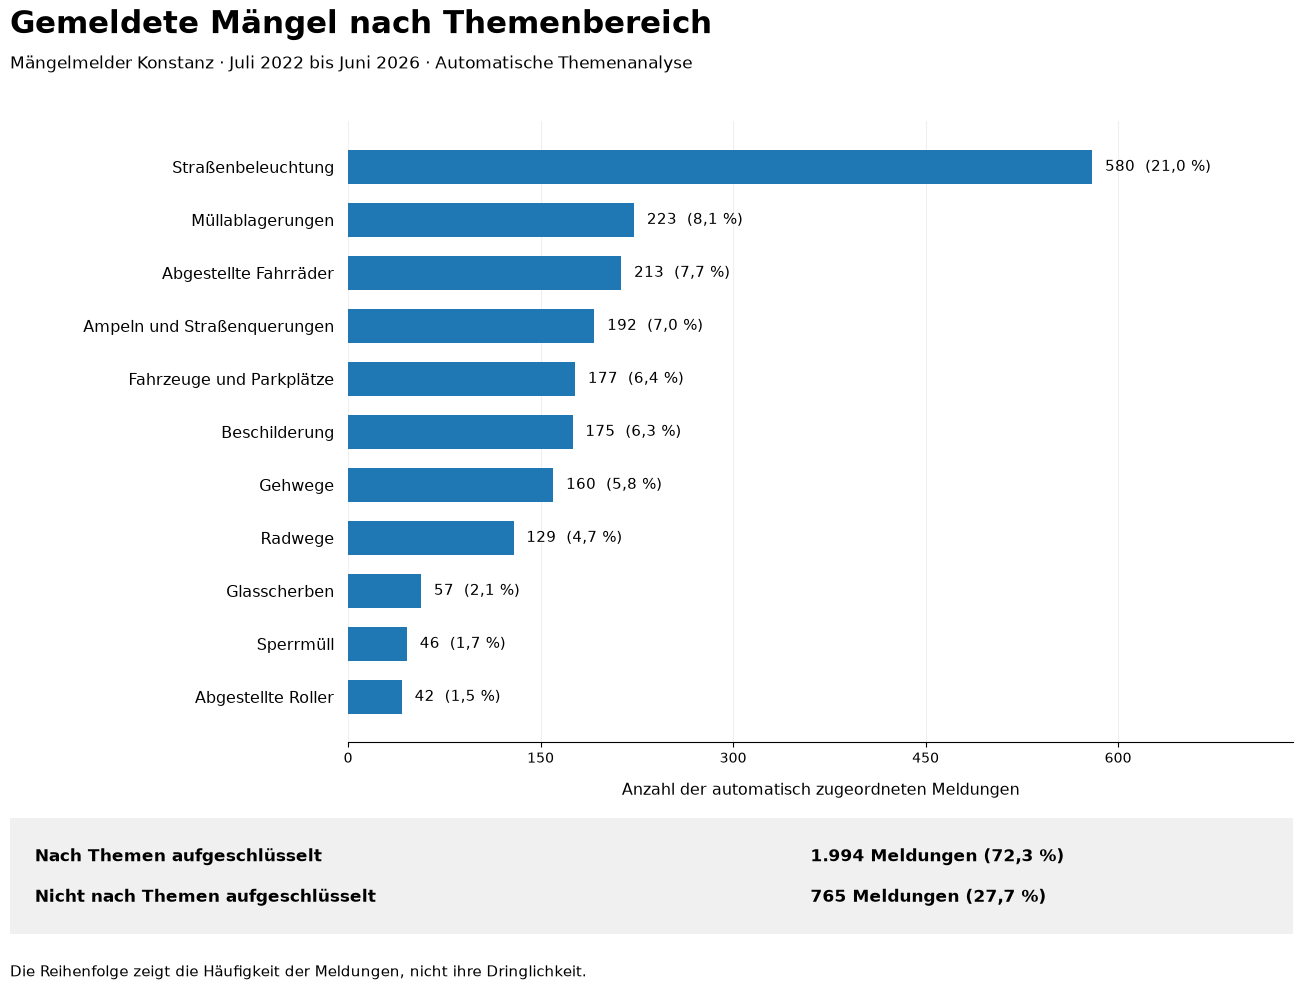

In [26]:
# Schritt 18 Gemeldete Mängel nach Themenbereich als Balkendiagramm darstellen
import matplotlib.pyplot as plt
report_start, report_end, period_label = result_view.result_period(df_model["date_created"])

result_image = OUTPUT_DIR / "themenhaeufigkeiten_nmf.png"
figure = result_view.plot_result_view(decision_table_final, decision_coverage, result_image, period_label)
plt.show()
plt.close(figure)
result_paths = [path for path in result_paths if path.name != result_image.name] + [result_image]
result_settings["diagramm"] = {
    "titel": "Gemeldete Mängel nach Themenbereich",
    "untertitel": f"Mängelmelder Konstanz · {period_label} · Automatische Themenanalyse",
    "zeitraum_von": report_start.date().isoformat(),
    "zeitraum_bis": report_end.date().isoformat(),
    "zeitraum_grundlage": "date_created der Meldungen nach dem Text Preprocessing",
    "darstellung_umfang": "Abgesetzter grauer Informationsbereich, kein weiterer Themenbalken",
    "hinweis": "Die Reihenfolge zeigt die Häufigkeit der Meldungen, nicht ihre Dringlichkeit.",
}
result_settings["sha256_ausgaben"] = {path.name: hashlib.sha256(path.read_bytes()).hexdigest() for path in result_paths}
result_settings_path = OUTPUT_DIR / "einstellungen_ergebnisdarstellung.json"
result_settings_path.write_text(json.dumps(result_settings, ensure_ascii=False, indent=2, default=str) + "\n", encoding="utf-8")
result_archive = OUTPUT_DIR / "ergebnisdarstellung_nmf15.zip"
with zipfile.ZipFile(result_archive, "w", compression=zipfile.ZIP_DEFLATED) as bundle:
    for path in result_paths + [result_settings_path]:
        bundle.write(path, arcname=path.name)
print("Gespeichert:", result_archive.resolve())


## Diskussion der Ergebnisse

In der automatischen Auswertung bildet die Straßenbeleuchtung mit 580 Meldungen (21,0 %) den größten Schwerpunkt. Es folgen Müllablagerungen mit 223 Meldungen (8,1 %), abgestellte Fahrräder mit 213 Meldungen (7,7 %) sowie Ampeln und Straßenquerungen mit 192 Meldungen (7,0 %). Die Analyse macht damit wiederkehrende Themen im Datensatz sichtbar und bietet eine Grundlage für die gezielte weitere Sichtung der Meldungen.

Die Ergebnisübersicht umfasst elf Themen mit insgesamt 1.994 Meldungen. Weitere 737 Meldungen liegen in vier inhaltlich gemischten Topics, 28 Meldungen enthalten keine Merkmale des verwendeten Vokabulars. Diese 765 Meldungen werden nicht nach Themen aufgeschlüsselt. Auch zwischen den dargestellten Themen gibt es inhaltliche Überschneidungen, beispielsweise bei Glasscherben auf Radwegen.

Für Entscheidungstragende eignet sich die Übersicht zur Orientierung über häufig gemeldete Anliegen. Die Reihenfolge beschreibt deren Häufigkeit, nicht ihre Dringlichkeit. Eine mögliche Weiterentwicklung wäre die Auswertung der Themen im Zeitverlauf.
